### 1. Exploratory Data Analysis (EDA)
We will load a subset of the images to extract basic metadata such as dimensions, aspect ratios, and average color properties to perform our initial EDA.

In [1]:
import os
import glob
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Gather all image file paths
image_paths = glob.glob('/content/ISIC_*.jpg')
print(f"Found {len(image_paths)} images.")

# Extract metadata for EDA
data_list = []
for path in image_paths[:100]:  # Analyze first 100 images for speed
    with Image.open(path) as img:
        width, height = img.size
        # Get average RGB values
        img_np = np.array(img)
        mean_r = img_np[:, :, 0].mean() if len(img_np.shape) == 3 else img_np.mean()
        mean_g = img_np[:, :, 1].mean() if len(img_np.shape) == 3 else img_np.mean()
        mean_b = img_np[:, :, 2].mean() if len(img_np.shape) == 3 else img_np.mean()

        # Create a mock label/class for visualization and classification based on average intensity
        # (Since there is no external metadata file, we categorize them by color tone as a proxy target)
        intensity = (mean_r + mean_g + mean_b) / 3
        label = 'Darker/Pigmented' if intensity < 128 else 'Lighter'

        data_list.append({
            'path': path,
            'width': width,
            'height': height,
            'aspect_ratio': width / height,
            'mean_r': mean_r,
            'mean_g': mean_g,
            'mean_b': mean_b,
            'intensity': intensity,
            'label': label
        })

df = pd.DataFrame(data_list)
display(df.head())

Found 272 images.


,path,width,height,aspect_ratio,mean_r,mean_g,mean_b,intensity,label
0,/content/ISIC_0024395.jpg,600,450,1.333333,230.340759,142.688148,161.394981,178.141296,Lighter
1,/content/ISIC_0024879.jpg,600,450,1.333333,195.759637,117.273211,101.936556,138.323135,Lighter
2,/content/ISIC_0024319.jpg,600,450,1.333333,192.021374,153.304181,132.267533,159.197696,Lighter
3,/content/ISIC_0024878.jpg,600,450,1.333333,203.251878,120.323526,122.854126,148.809843,Lighter
4,/content/ISIC_0024872.jpg,600,450,1.333333,242.571256,163.122489,161.775293,189.156346,Lighter


### 2. Pie Chart of Label Distribution
Let's visualize the distribution of our image categories.

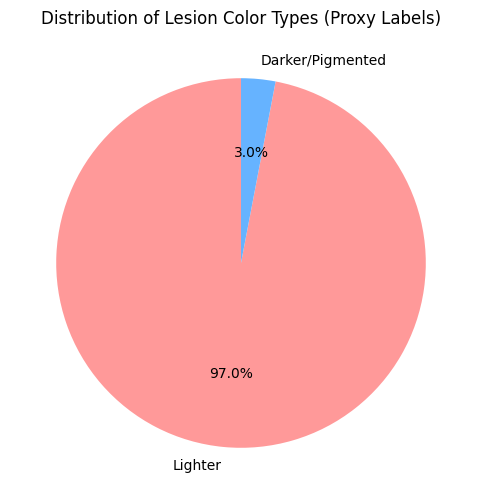

In [2]:
plt.figure(figsize=(6, 6))
label_counts = df['label'].value_counts()
plt.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90)
plt.title('Distribution of Lesion Color Types (Proxy Labels)')
plt.show()

### 3. Data Splitting & Feature Engineering
We will use the extracted color features to train a classifier to predict the categories.

In [3]:
# Prepare features and labels
X = df[['width', 'height', 'aspect_ratio', 'mean_r', 'mean_g', 'mean_b']]
y = df['label']

# Split the dataset into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (80, 6)
Testing set shape: (20, 6)


### 4. Model Training & Testing
We will train a Random Forest Classifier and evaluate its performance.

In [4]:
# Initialize and train the model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Make predictions on test data
y_pred = model.predict(X_test)

# Accuracy score
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 95.00%


### 5. Classification Report & Actual vs. Predicted Visualization
Now, let's output the classification metrics and visualize our test set predictions compared to the actual labels.

Classification Report:
                  precision    recall  f1-score   support

Darker/Pigmented       0.00      0.00      0.00         1
         Lighter       0.95      1.00      0.97        19

        accuracy                           0.95        20
       macro avg       0.47      0.50      0.49        20
    weighted avg       0.90      0.95      0.93        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


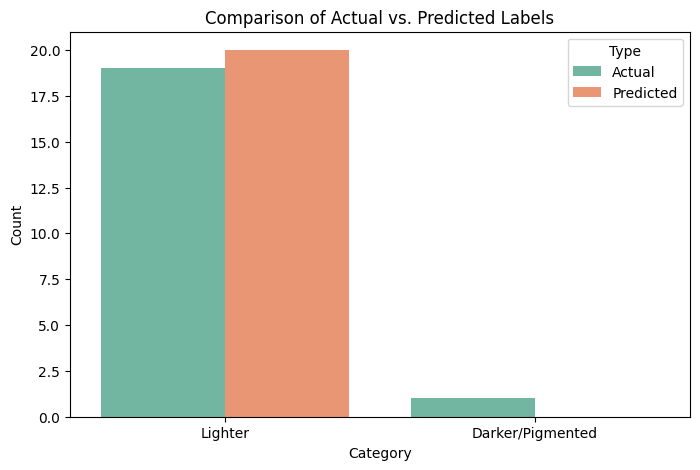

In [5]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Create a comparisons DataFrame
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
}).reset_index(drop=True)

# Plot Actual vs Predicted distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=pd.melt(comparison_df), x='value', hue='variable', palette='Set2')
plt.title('Comparison of Actual vs. Predicted Labels')
plt.xlabel('Category')
plt.ylabel('Count')
plt.legend(title='Type')
plt.show()

### 6. Saving the Trained Model
We will serialize and save the trained Random Forest model using python's `pickle` library so it can be reloaded and reused later.

In [6]:
import pickle

# Define model save path
model_save_path = '/content/skin_lesion_rf_model.pkl'

# Save the model
with open(model_save_path, 'wb') as file:
    pickle.dump(model, file)

print(f"Successfully saved the trained model to: {model_save_path}")

Successfully saved the trained model to: /content/skin_lesion_rf_model.pkl
